# Part A - Insurance Claim Prediction

**Goal:** predict whether a policy ends up with an insurance claim (`insuranceclaim` = 1) using customer details such as age, BMI, smoking status and number of children.

I'll work through it the way I'd explain it to a colleague: look at the data, understand it, clean it up properly, then build and honestly judge a few models.

**How the notebook is laid out**
1. Dataset understanding
2. Exploratory data analysis
3. Preprocessing (without leaking test information)
4. Models and evaluation
5. Short answers to the written questions

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, RocCurveDisplay, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
sns.set_theme(style="whitegrid"); RANDOM_STATE = 42

## Task 1 - Getting to know the dataset

In [2]:
df = pd.read_csv("insurance2__1_.csv")
print("First 5 records"); display_head = df.head(); print(display_head.to_string())
print("\nLast 5 records"); print(df.tail().to_string())
print(f"\nRows: {df.shape[0]}  |  Columns: {df.shape[1]}")
print("\nColumn names:", list(df.columns))
print("\nData types:"); print(df.dtypes.to_string())
print("\nMissing values per column:"); print(df.isna().sum().to_string())
print("\nExact duplicate rows:", df.duplicated().sum())

First 5 records
   age  sex     bmi  children  smoker  region      charges  insuranceclaim
0   19    0  27.900         0       1       3  16884.92400               1
1   18    1  33.770         1       0       2   1725.55230               1
2   28    1  33.000         3       0       2   4449.46200               0
3   33    1  22.705         0       0       1  21984.47061               0
4   32    1  28.880         0       0       1   3866.85520               1

Last 5 records
      age  sex    bmi  children  smoker  region     charges  insuranceclaim
1333   50    1  30.97         3       0       1  10600.5483               0
1334   18    0  31.92         0       0       0   2205.9808               1
1335   18    0  36.85         0       0       2   1629.8335               1
1336   21    0  25.80         0       0       3   2007.9450               0
1337   61    0  29.07         0       1       1  29141.3603               1

Rows: 1338  |  Columns: 8

Column names: ['age', 'sex', 'bmi'

**What I see:** the file has **1,338 rows and 8 columns**, with **no missing values**. There's exactly one fully duplicated row; at this size it makes no real difference, so I've left it in rather than quietly altering the data.

Every column is stored as a number, but that doesn't mean every column *is* a number in the everyday sense, so let me answer the questions properly.

In [3]:
print(df.describe().round(2).to_string())
counts = df["insuranceclaim"].value_counts().sort_index()
print("\nTarget distribution:"); print(pd.DataFrame({"count": counts, "share_%": (counts/len(df)*100).round(1)}).to_string())

           age      sex      bmi  children  smoker   region   charges  insuranceclaim
count  1338.00  1338.00  1338.00   1338.00  1338.0  1338.00   1338.00         1338.00
mean     39.21     0.51    30.66      1.09     0.2     1.52  13270.42            0.59
std      14.05     0.50     6.10      1.21     0.4     1.10  12110.01            0.49
min      18.00     0.00    15.96      0.00     0.0     0.00   1121.87            0.00
25%      27.00     0.00    26.30      0.00     0.0     1.00   4740.29            0.00
50%      39.00     1.00    30.40      1.00     0.0     2.00   9382.03            1.00
75%      51.00     1.00    34.69      2.00     0.0     2.00  16639.91            1.00
max      64.00     1.00    53.13      5.00     1.0     3.00  63770.43            1.00

Target distribution:
                count  share_%
insuranceclaim                
0                 555     41.5
1                 783     58.5


### Questions to answer

**1. Which variables are numerical?**
`age`, `bmi` and `charges` are genuinely numeric (continuous). `children` is numeric too, but it's a small count (0-5).

**2. Which variables are categorical?**
`sex`, `smoker` and `region` are categories that happen to be stored as numbers. `sex` and `smoker` are simple yes/no style flags (0/1). `region` uses codes 0-3 with no natural order (code 3 is not "more" than code 1), so I treat it as a nominal category and one-hot encode it. The target `insuranceclaim` is also binary.

**3. What is the target variable?**
`insuranceclaim` - 1 means the policy resulted in a claim, 0 means it didn't. It's a binary classification problem.

**4. Is the target balanced?**
Reasonably. 783 policies (58.5%) have a claim and 555 (41.5%) don't. That's a mild tilt towards claims, not a serious imbalance, so I don't need resampling tricks. I will still use *stratified* splits so train and test keep the same 58/42 mix, and I'll look at precision, recall and F1 and not just accuracy.

## Task 2 - Exploratory data analysis (univariate)

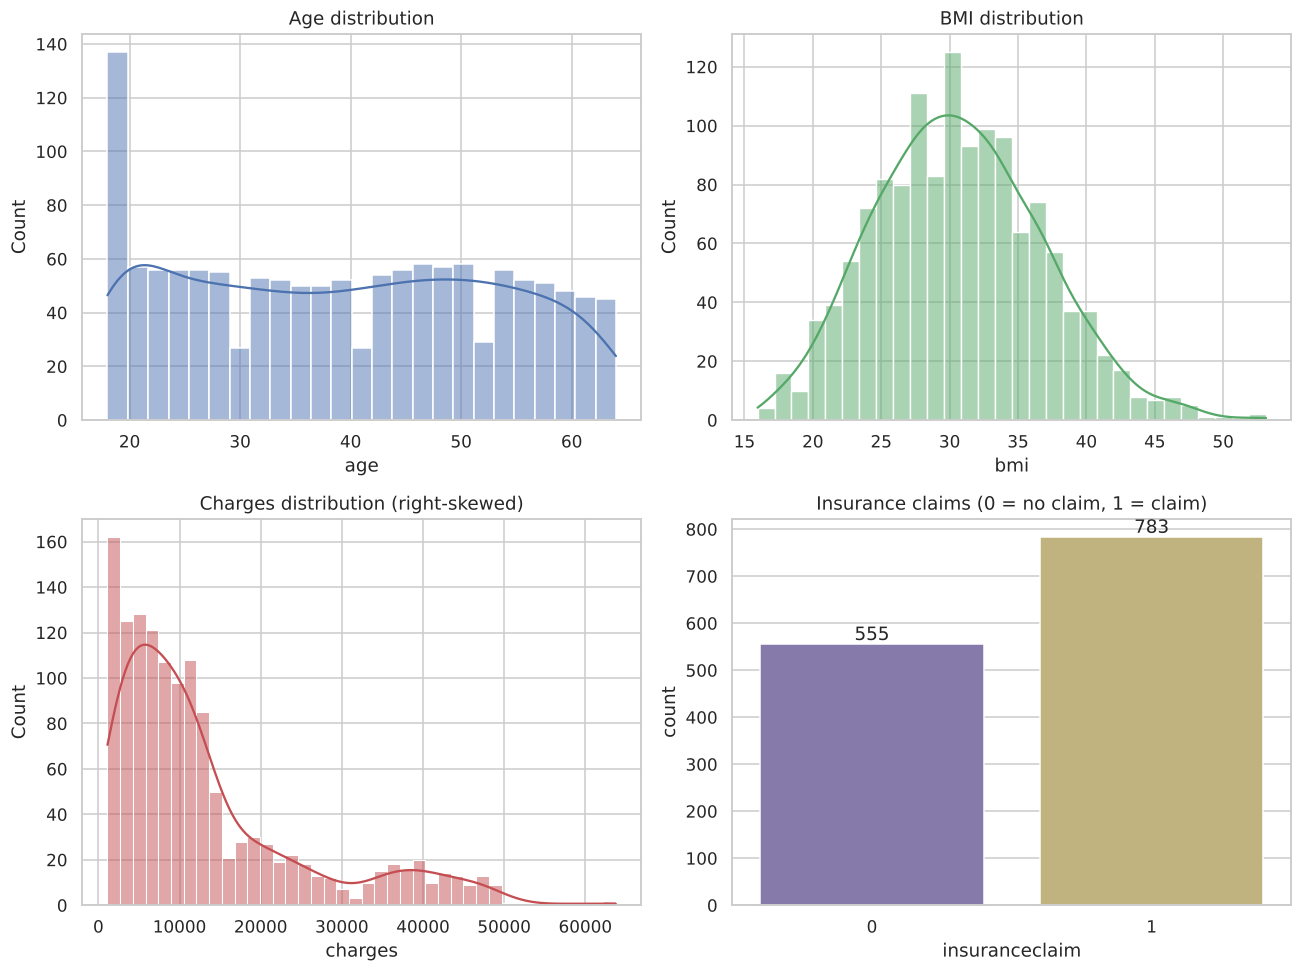

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
sns.histplot(df["age"], bins=25, kde=True, ax=ax[0,0], color="#4C72B0"); ax[0,0].set_title("Age distribution")
sns.histplot(df["bmi"], bins=30, kde=True, ax=ax[0,1], color="#55A868"); ax[0,1].set_title("BMI distribution")
sns.histplot(df["charges"], bins=40, kde=True, ax=ax[1,0], color="#C44E52"); ax[1,0].set_title("Charges distribution (right-skewed)")
sns.countplot(x="insuranceclaim", data=df, ax=ax[1,1], palette=["#8172B2", "#CCB974"], hue="insuranceclaim", legend=False)
ax[1,1].set_title("Insurance claims (0 = no claim, 1 = claim)")
for p in ax[1,1].patches: ax[1,1].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout()

**Reading the plots**
- **Age** is spread fairly evenly from 18 to 64, with a bump of very young customers at the left edge. No odd outliers.
- **BMI** looks like a bell curve centred around 30, with a long tail up to 53. A lot of customers sit in the overweight/obese range.
- **Charges** is strongly right-skewed (skew about 1.5): most people are charged a few thousand, while a small group runs past 40,000. That's typical for cost data. Tree-based models don't mind; for logistic regression the scaler helps, though a log transform could be tried as a next step.
- **Claims** shows the 58.5% / 41.5% split from above.

A few extra views, beyond what was asked, because they explain the model results later:

                 age   bmi  charges
insuranceclaim                     
0               37.3  27.9   8821.4
1               40.6  32.6  16423.9


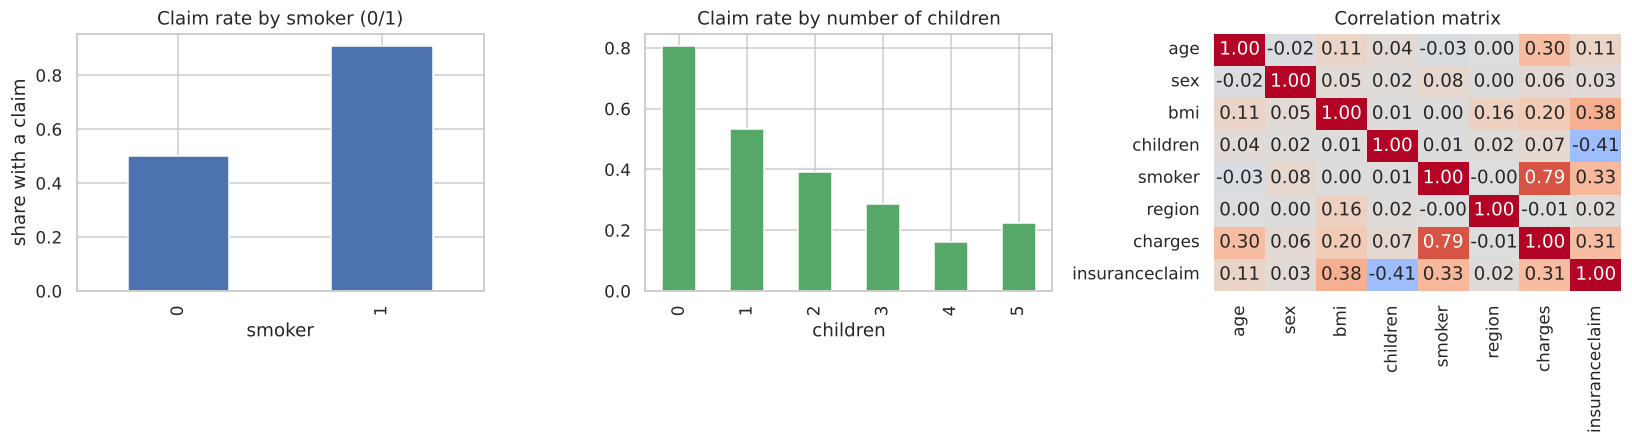

In [5]:
# A few extra looks at how features relate to the target (not required, but they explain the model later)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
df.groupby("smoker")["insuranceclaim"].mean().plot.bar(ax=ax[0], color="#4C72B0"); ax[0].set_title("Claim rate by smoker (0/1)"); ax[0].set_ylabel("share with a claim")
df.groupby("children")["insuranceclaim"].mean().plot.bar(ax=ax[1], color="#55A868"); ax[1].set_title("Claim rate by number of children")
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[2], cbar=False); ax[2].set_title("Correlation matrix")
plt.tight_layout()
print(df.groupby("insuranceclaim")[["age","bmi","charges"]].mean().round(1).to_string())

Three things stand out:
- **Smokers claim far more often** - about 91% of smokers have a claim vs about 50% of non-smokers.
- **More children means fewer claims** in this data (about 81% claim with 0 children, falling to about 29% with 3). That's surprising and worth a conversation with the business rather than something I'd read as cause and effect.
- Customers with a claim have a higher average BMI (32.6 vs 27.9) and higher charges (about 16.4k vs 8.8k).

## Task 3 - Preprocessing

My steps:
1. Split features (`X`) from the target (`y`).
2. **Split into train/test first** (80/20, stratified).
3. Encode: one-hot `region`; leave the already-binary `sex` and `smoker` as 0/1.
4. Scale `age`, `bmi`, `children`, `charges` with `StandardScaler`.
5. Wrap steps 3-4 in a scikit-learn `ColumnTransformer` inside a `Pipeline`, so the scaler and encoder are **fitted on training data only** and merely *applied* to the test data. That's how I avoid data leakage.

In [6]:
# Task 3: features / target, split FIRST, then fit transformers on training data only
X = df.drop(columns="insuranceclaim"); y = df["insuranceclaim"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Claim share  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

numeric_cols = ["age", "bmi", "children", "charges"]   # scaled
nominal_cols = ["region"]                                # integer codes 0-3 with no real order -> one-hot
binary_cols  = ["sex", "smoker"]                         # already 0/1, left as-is
def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), numeric_cols),
        ("region", OneHotEncoder(drop="first", handle_unknown="ignore"), nominal_cols),
        ("bin", "passthrough", binary_cols)])

Train: (1070, 7)  Test: (268, 7)
Claim share  train: 0.585  test: 0.586


In [7]:
# Tiny demo of why leakage matters: the "full data" mean differs from what training alone knows
print("Charges mean  -> train only: %.1f | full dataset: %.1f | test only: %.1f" % (X_train.charges.mean(), X.charges.mean(), X_test.charges.mean()))

Charges mean  -> train only: 13023.5 | full dataset: 13270.4 | test only: 14256.4


Look at the numbers: the average charge is 13,024 in the training set, 13,270 in the full data and 14,256 in the test set. If I'd scaled using the full dataset, the scaler would quietly "know" something about the test rows.

### Question: why learn the transformations from the training data only?

Because the test set is supposed to behave like **future customers we haven't seen yet**. When a scaler computes a mean and standard deviation (or an encoder learns the categories), it is *learning from data*. If it learns from the whole dataset, information about the test rows leaks into training. The model then gets a small, invisible head start, and the test score looks better than the model will actually perform once deployed.

In real life, when a new customer arrives, we can only use what we learned from past customers. So we mimic that: **fit on train, then transform both train and test with those same learned values.** The same logic applies inside cross-validation, which is why I put everything in a pipeline, so each fold re-learns its own scaling from only its own training portion.

## Task 4 - Building and evaluating models

I tried three models to see how much extra power is actually needed:
- **Logistic Regression** - a simple, explainable baseline.
- **Random Forest** - handles non-linear patterns and interactions.
- **Gradient Boosting** - often the strongest on tabular data.

First I compare them using 5-fold cross-validation **on the training set only**, so the test set stays untouched until the end.

In [8]:
# Task 4: three candidate models, every one wrapped in a Pipeline so scaling/encoding is learned inside each CV fold
models = {
  "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
  "Random Forest":       RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
  "Gradient Boosting":   GradientBoostingClassifier(random_state=RANDOM_STATE)}
pipes = {n: Pipeline([("prep", make_preprocessor()), ("model", m)]) for n, m in models.items()}
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for n, p in pipes.items():
    rows.append({"model": n,
                 "cv_accuracy": cross_val_score(p, X_train, y_train, cv=cv, scoring="accuracy").mean(),
                 "cv_f1":       cross_val_score(p, X_train, y_train, cv=cv, scoring="f1").mean(),
                 "cv_roc_auc":  cross_val_score(p, X_train, y_train, cv=cv, scoring="roc_auc").mean()})
cv_table = pd.DataFrame(rows).set_index("model").round(3); print("5-fold CV on the TRAINING set only:"); print(cv_table.to_string())

5-fold CV on the TRAINING set only:
                     cv_accuracy  cv_f1  cv_roc_auc
model                                              
Logistic Regression        0.882  0.901       0.926
Random Forest              0.956  0.962       0.992
Gradient Boosting          0.974  0.978       0.995


The two tree-based models are well ahead of logistic regression, which suggests the relationship between the features and a claim is not a straight line. A small grid search (again only on training data) tunes them:

In [9]:
# Light tuning for the two tree ensembles (still only training data)
grids = {"Random Forest": {"model__max_depth": [4, 6, 8, None], "model__min_samples_leaf": [1, 3, 5]},
         "Gradient Boosting": {"model__n_estimators": [100, 200], "model__learning_rate": [0.03, 0.1], "model__max_depth": [2, 3]}}
tuned = {"Logistic Regression": pipes["Logistic Regression"].fit(X_train, y_train)}
for n, g in grids.items():
    gs = GridSearchCV(pipes[n], g, cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
    tuned[n] = gs.best_estimator_; print(f"{n}: best CV ROC-AUC {gs.best_score_:.3f} with {gs.best_params_}")

Random Forest: best CV ROC-AUC 0.992 with {'model__max_depth': None, 'model__min_samples_leaf': 1}
Gradient Boosting: best CV ROC-AUC 0.996 with {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}


Now the one-time evaluation on the held-out test set, including the predictions and the predicted claim probabilities (`P(claim)`):

In [10]:
# Predictions, probabilities and test-set evaluation (test set touched once, here)
res, preds, probs = [], {}, {}
for n, est in tuned.items():
    preds[n] = est.predict(X_test); probs[n] = est.predict_proba(X_test)[:, 1]
    res.append({"model": n, "accuracy": accuracy_score(y_test, preds[n]), "precision": precision_score(y_test, preds[n]),
                "recall": recall_score(y_test, preds[n]), "f1": f1_score(y_test, preds[n]), "roc_auc": roc_auc_score(y_test, probs[n])})
results = pd.DataFrame(res).set_index("model").round(3); print(results.to_string())
best = results["roc_auc"].idxmax(); print("\nBest by ROC-AUC:", best)
print("\nSample of predictions with probabilities (best model):")
print(pd.DataFrame({"actual": y_test.values[:8], "predicted": preds[best][:8], "P(claim)": probs[best][:8].round(3)}).to_string(index=False))

                     accuracy  precision  recall     f1  roc_auc
model                                                           
Logistic Regression     0.858      0.879   0.879  0.879    0.903
Random Forest           0.963      0.962   0.975  0.968    0.992
Gradient Boosting       0.981      0.981   0.987  0.984    0.993

Best by ROC-AUC: Gradient Boosting

Sample of predictions with probabilities (best model):
 actual  predicted  P(claim)
      1          1     1.000
      1          1     0.957
      0          0     0.001
      1          1     1.000
      1          1     1.000
      0          0     0.000
      1          1     1.000
      0          0     0.001


The detailed breakdown for the best model:

              precision    recall  f1-score   support

    no claim       0.98      0.97      0.98       111
       claim       0.98      0.99      0.98       157

    accuracy                           0.98       268
   macro avg       0.98      0.98      0.98       268
weighted avg       0.98      0.98      0.98       268

TN=108 FP=3 FN=2 TP=155


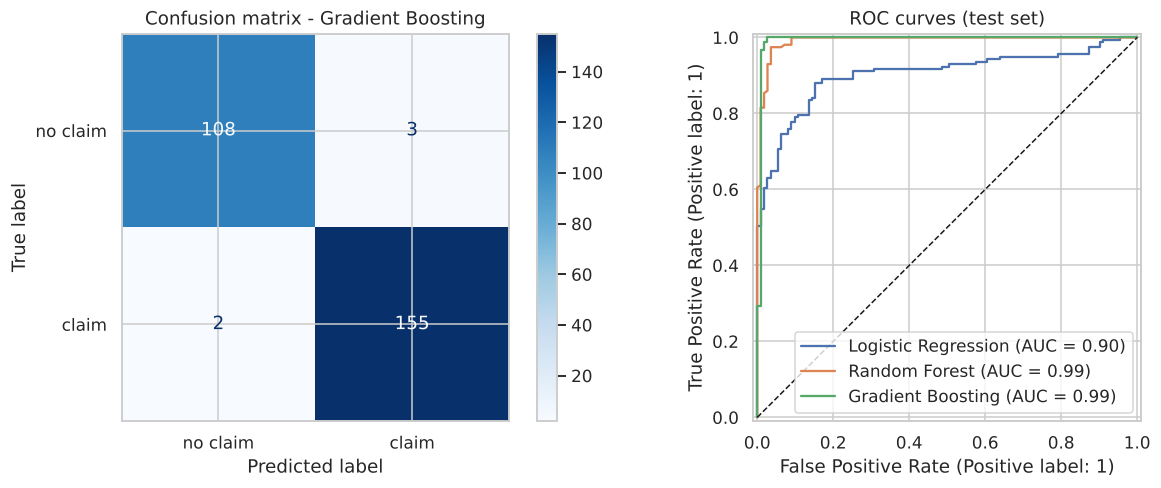

In [11]:
print(classification_report(y_test, preds[best], target_names=["no claim", "claim"]))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ConfusionMatrixDisplay.from_predictions(y_test, preds[best], display_labels=["no claim", "claim"], cmap="Blues", ax=ax[0]); ax[0].set_title(f"Confusion matrix - {best}")
for n in tuned: RocCurveDisplay.from_predictions(y_test, probs[n], name=n, ax=ax[1])
ax[1].plot([0,1],[0,1],"k--",lw=1); ax[1].set_title("ROC curves (test set)")
plt.tight_layout()
tn, fp, fn, tp = confusion_matrix(y_test, preds[best]).ravel(); print(f"TN={tn} FP={fp} FN={fn} TP={tp}")

**How to read this:** out of 268 test policies, the Gradient Boosting model got 263 right. It missed 2 real claims (false negatives) and wrongly flagged 3 non-claims (false positives). Precision, recall and F1 are all about 0.98 and the ROC-AUC is 0.99.

Logistic Regression is clearly the weakest (accuracy 0.86, ROC-AUC 0.90) but still decent and the easiest to explain.

bmi         0.236
children    0.212
smoker      0.100
age         0.022
charges     0.019
region      0.000
sex        -0.000


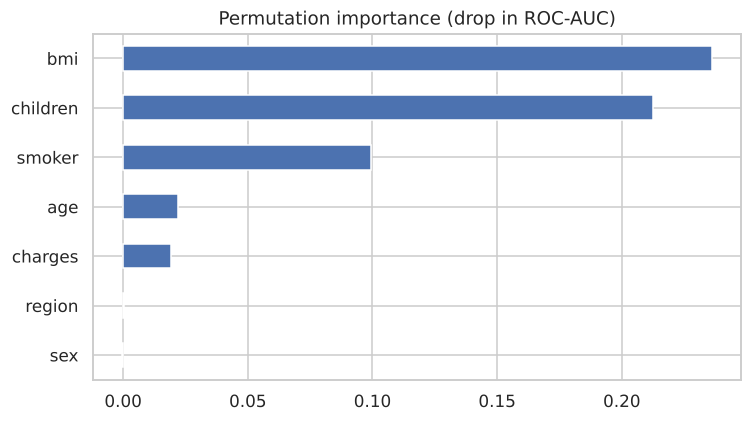

In [12]:
# What is the model actually using?  (permutation importance on the test set)
pi = permutation_importance(tuned[best], X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=RANDOM_STATE)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
imp.plot.barh(figsize=(7,4), color="#4C72B0"); plt.title("Permutation importance (drop in ROC-AUC)"); plt.tight_layout()
print(imp.sort_values(ascending=False).round(3).to_string())

`bmi`, `children` and `smoker` do almost all of the work. `age` and `charges` add little and `sex` and `region` add essentially nothing. This matches what the EDA showed.

In [13]:
# Sanity check: charges may only be known AFTER a claim is paid. How much do we lean on it?
Xtr2, Xte2 = X_train.drop(columns="charges"), X_test.drop(columns="charges")
num2 = [c for c in numeric_cols if c != "charges"]
prep2 = ColumnTransformer([("num", StandardScaler(), num2), ("region", OneHotEncoder(drop="first"), nominal_cols), ("bin","passthrough",binary_cols)])
alt = Pipeline([("prep", prep2), ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))]).fit(Xtr2, y_train)
p2 = alt.predict_proba(Xte2)[:,1]
print("Gradient Boosting WITHOUT charges -> accuracy %.3f | recall %.3f | ROC-AUC %.3f" % (accuracy_score(y_test, alt.predict(Xte2)), recall_score(y_test, alt.predict(Xte2)), roc_auc_score(y_test, p2)))
print("Gradient Boosting WITH charges    -> accuracy %.3f | recall %.3f | ROC-AUC %.3f" % (results.loc["Gradient Boosting","accuracy"], results.loc["Gradient Boosting","recall"], results.loc["Gradient Boosting","roc_auc"]))

Gradient Boosting WITHOUT charges -> accuracy 0.985 | recall 0.987 | ROC-AUC 0.996
Gradient Boosting WITH charges    -> accuracy 0.981 | recall 0.987 | ROC-AUC 0.993


I wondered whether `charges` was "cheating", since the amount charged might only be known *after* a claim. Dropping it doesn't hurt: the score is basically the same or slightly better. So the model isn't leaning on it, which is reassuring. In a real deployment I'd still confirm with the business when `charges` becomes available.

### An honest caveat about these scores

98% accuracy on insurance data is unusually high. Real claim behaviour is noisy, so I suspect this dataset is partly synthetic, with claims generated from a fairly clean rule on BMI, children and smoking. The model has learned that rule well, but I wouldn't expect the same performance on real-world policies without re-testing on genuine data.

**Final choice:** Gradient Boosting for accuracy; Logistic Regression if explainability matters more than the last few points of performance.

## Questions on deployment and interpretation

**1. What would the target variable be?**
`insuranceclaim` (1 = the policy produced a claim, 0 = it did not).

**2. Which evaluation metrics would you consider?**
Accuracy is fine here since classes are roughly balanced, but it shouldn't be the only number. I'd look at **recall** (how many real claims we catch), **precision** (how many flagged policies really claim), **F1** to balance the two, the **confusion matrix** for the actual counts, and **ROC-AUC** to judge how well the model ranks risk regardless of the cut-off. If the business cares about a particular trade-off, I'd tune the probability threshold rather than leave it at 0.5.

**3. Why could false negatives be particularly important?**
A false negative means a policy the model called "no claim" that then did claim. The insurer under-prices or under-reserves for that risk, and in a health setting a high-need person could be treated as low-need and miss out on proactive support. A false positive usually costs less: some extra review or a slightly higher premium estimate. So I'd lean toward higher recall, accepting a few more false alarms. (In our test, only 2 of 157 real claims were missed.)

**4. How would you explain the prediction to a healthcare professional?**
In plain language and without jargon: *"The model estimates the likelihood that this person will make a claim, based mainly on BMI, number of children and smoking status. For this person it says 87%, which is high. It's a risk indicator to prioritise a conversation or review, not a diagnosis or a verdict."* I'd show the top two or three factors behind each score (like the importance chart above), say how often the model is right, and stress that a clinician's judgement comes first.

**5. What risks should be considered before deploying the model?**
- **Too-good-to-be-true accuracy** - likely synthetic or simplified data; validate on real, recent policies.
- **Fairness and ethics** - the model shouldn't discriminate, and using things like BMI or smoking to deny cover or raise prices has legal and ethical implications. `sex` and `region` should be monitored for bias even if they carry little weight.
- **Data drift** - customer mix, pricing and behaviour change, so performance should be monitored and the model retrained.
- **Privacy** - health-related data needs strict protection and consent (e.g. GDPR/HIPAA-style rules).
- **Human oversight** - predictions should support, not replace, an underwriter or clinician, and customers should have a route to challenge decisions.
- **Correlation vs causation** - for example, "more children, fewer claims" is a pattern in this data, not a rule of nature.